# Where sunlight goes: surface balance from Sentinel-2

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/radiation_balance_en.ipynb)

**OpenSkyLab · notebook for the visual** [Where radiation goes](https://openskylab.space/edu_viz_radiation_balance.html) · [česká verze](radiation_balance_cs.ipynb)

In the visual, incoming radiation splits into reflected, absorbed and transmitted parts, ρ + α + τ = 1, and Kirchhoff's law gives ε = α. Here you measure reflectance on real Sentinel-2 pixels (forest, meadow, field, built-up area, water and snow), compute how much radiation the surfaces absorb in real weather and estimate how warm they get.

**Goal:** compute absorptance and albedo of surfaces from real reflectance, apply Kirchhoff's law to snow and metals, and estimate the equilibrium surface temperature from an energy balance with current weather, then design a cool roof.

**Data:** Sentinel-2 L2A (surface reflectance) from the Earth Search catalogue on AWS: scene `S2B_33UVR_20240721_0_L2A` (21 July 2024, near Roztoky u Prahy) and `S2A_33UWS_20240308_0_L2A` (8 March 2024, snow in the Krkonoše mountains); land-cover classes from ESA WorldCover 2021; hourly weather for Prague from Open-Meteo (last 92 days). About 15 MB is downloaded.

**Tasks:** six. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 40 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
from scipy.optimize import brentq

STAC = "https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E012_Map.tif"
BANDS = ["coastal", "blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def read_on_grid(url, grid, resampling=Resampling.bilinear, dtype=np.float32):
    """Read a cloud raster and resample it to grid = (transform, crs, height, width)."""
    tr, crs, ny, nx = grid
    out = np.zeros((ny, nx), dtype)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + url) as src:
            reproject(rasterio.band(src, 1), out, dst_transform=tr, dst_crs=crs, resampling=resampling)
    return out

def s2_window(item_id, lon, lat, half):
    """Reflectance of all Sentinel-2 L2A bands in a square around a point (10 m grid in the tile's UTM)."""
    item = requests.get(STAC + item_id, timeout=60).json()
    epsg = item["properties"]["proj:epsg"] if "proj:epsg" in item["properties"] else int(item["properties"]["proj:code"].split(":")[1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(2 * half / 10)
    grid = (rasterio.transform.from_origin(x - half, y + half, 10, 10), f"EPSG:{epsg}", n, n)
    # since processing baseline 04.00 (2022) DN carry a +1000 offset; Earth Search has already removed it for newer items
    p = item["properties"]
    offset = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    refl = {b: (read_on_grid(item["assets"][b]["href"], grid) + offset) / 10000 for b in BANDS}
    scl = read_on_grid(item["assets"]["scl"]["href"], grid, Resampling.nearest, np.uint8)
    wl = {b: item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in BANDS}
    return refl, scl, wl, grid, item

def open_meteo(params, tries=6):
    """Query Open-Meteo; retry on errors or when the daily limit is exceeded."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo is not responding, run the cell again in a while.")

## 2. Reflectance of real surfaces

We load a 3 × 3 km window around Roztoky and for each ESA WorldCover class take the median reflectance of clear pixels (no clouds or shadows according to the SCL mask). We add snow from the Krkonoše mountains.

In [3]:
refl, scl, wl, grid, item = s2_window("S2B_33UVR_20240721_0_L2A", 14.375, 50.145, 1500)
wc = read_on_grid(WORLDCOVER, grid, Resampling.nearest, np.uint8)
clear = np.isin(scl, [4, 5, 6])                     # 4 vegetation, 5 bare surface, 6 water
classes = {10: "forest", 30: "meadow", 40: "field", 50: "built-up", 80: "water"}
spectra = {}
for code, name in classes.items():
    m = clear & (wc == code)
    spectra[name] = [float(np.median(refl[b][m])) for b in BANDS]
    print(f"{name:9s}: {m.sum():6d} pixels")

snow_refl, snow_scl, *_ = s2_window("S2A_33UWS_20240308_0_L2A", 15.70, 50.735, 1500)
m = snow_scl == 11                                   # 11 = snow and ice
spectra["snow"] = [float(np.median(snow_refl[b][m])) for b in BANDS]
print(f"snow     : {m.sum():6d} pixels")
R = pd.DataFrame(spectra, index=pd.Index([wl[b] for b in BANDS], name="λ (µm)"))
R.round(3)

forest   :  39005 pixels
meadow   :  11347 pixels
field    :  27090 pixels
built-up :  11150 pixels
water    :   1058 pixels


snow     :  88400 pixels


,forest,meadow,field,built-up,water,snow
λ (µm),,,,,,
0.443,0.031,0.040,0.048,0.060,0.028,0.714
0.490,0.032,0.048,0.066,0.074,0.028,0.751
0.560,0.049,0.075,0.086,0.091,0.030,0.780
0.665,0.029,0.063,0.118,0.099,0.022,0.810
0.704,0.079,0.123,0.141,0.131,0.024,0.833
0.740,0.248,0.263,0.170,0.213,0.015,0.814
0.783,0.313,0.307,0.186,0.244,0.017,0.784
0.842,0.322,0.318,0.189,0.237,0.012,0.794
0.865,0.338,0.335,0.207,0.256,0.012,0.761


## 3. Absorptance: α = 1 − ρ − τ

For the satellite a pixel is opaque: whatever is not reflected back is absorbed by the canopy, the soil or the water below. For the whole pixel α = 1 − ρ. (For a single leaf, τ in the NIR is about as large as ρ; inside a canopy the transmitted light is reflected and absorbed further.)

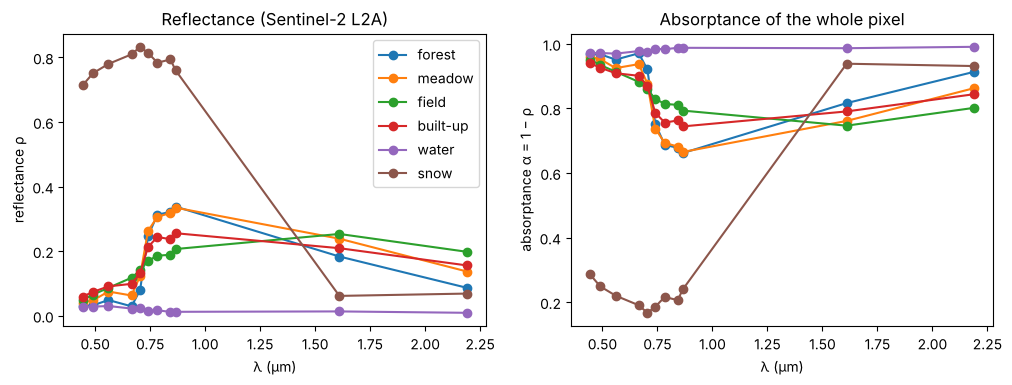

In [4]:
A = 1 - R
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
R.plot(ax=ax[0], marker="o"); ax[0].set(ylabel="reflectance ρ", title="Reflectance (Sentinel-2 L2A)")
A.plot(ax=ax[1], marker="o", legend=False); ax[1].set(ylabel="absorptance α = 1 − ρ", title="Absorptance of the whole pixel")
plt.show()

> **✏️ Task 1.** Where do forest and meadow absorb most and least? Why is it useful for a plant to absorb almost no NIR? Why does water absorb almost everything that enters it in the NIR?

*Your answer:* 

> **✏️ Task 2.** Snow is white in visible light. What is its absorptance at 1.6 µm (B11)? Kirchhoff's law gives ε = α at the same wavelength. Sentinel-2 has no thermal band (10 µm), but the trend from visible to SWIR hints at how snow behaves further on. Why is snow almost a blackbody in the thermal range (ε ≈ 0.99) and what does that mean for measuring its temperature with a thermal camera?

*Your answer:* 

## 4. Albedo: how much sunlight a surface reflects in total

Albedo is reflectance weighted by the solar spectrum. Liang (2001) derived it for Landsat bands as a linear combination; we use the corresponding Sentinel-2 bands (B2, B4, B8, B11, B12), so the result is approximate.

In [5]:
pick = lambda name, b: R[name].iloc[BANDS.index(b)]
albedo = pd.Series({name: 0.356 * pick(name, "blue") + 0.130 * pick(name, "red") + 0.373 * pick(name, "nir")
                         + 0.085 * pick(name, "swir16") + 0.072 * pick(name, "swir22") - 0.0018 for name in R.columns})
print(albedo.round(3).to_string())

forest      0.155
meadow      0.172
field       0.143
built-up    0.155
water       0.017
snow        0.677


## 5. Real weather and the energy balance

From Open-Meteo we take the sunniest hour of the last 92 days in Prague: global radiation S, air temperature, dew point and wind. A surface in equilibrium (no evaporation and no conduction into the ground) satisfies

(1 − albedo) · S + ε · L↓ = ε · σ · T⁴ + h · (T − T_air),

where L↓ is the longwave radiation of the sky (Brutsaert 1975, clear sky) and h = 5.7 + 3.8 · u is convective heat transfer.

In [6]:
w = open_meteo({"latitude": 50.08, "longitude": 14.42, "past_days": 92, "forecast_days": 1, "wind_speed_unit": "ms",
                "hourly": "shortwave_radiation,temperature_2m,dew_point_2m,wind_speed_10m,cloud_cover", "timezone": "UTC"})
met = pd.DataFrame(w["hourly"]).set_index("time")
row = met.loc[met.shortwave_radiation.idxmax()]
print("sunniest hour:", row.name, "UTC"); print(row.to_string())

Open-Meteo: SSLError – retrying


Open-Meteo: SSLError – retrying


sunniest hour: 2026-08-24T11:00 UTC
shortwave_radiation    783.00
temperature_2m          18.80
dew_point_2m             9.20
wind_speed_10m           1.31
cloud_cover             33.00


In [7]:
SIGMA = 5.670374e-8
S, Ta, Td = row.shortwave_radiation, row.temperature_2m + 273.15, row.dew_point_2m
u = row.wind_speed_10m * 0.75          # ◀ parameter: wind near the surface (about 3/4 of the 10 m wind)
e_a = 6.112 * np.exp(17.62 * Td / (243.12 + Td))                  # water vapour pressure (hPa), Magnus formula
L_sky = 1.24 * (e_a / Ta) ** (1 / 7) * SIGMA * Ta**4               # Brutsaert, clear sky
h_c = 5.7 + 3.8 * u

def t_equilibrium(albedo, eps, S=S, Ta=Ta, L_sky=L_sky, h_c=h_c):
    f = lambda T: (1 - albedo) * S + eps * L_sky - eps * SIGMA * T**4 - h_c * (T - Ta)
    return brentq(f, 200, 400) - 273.15

eps_surface = {"forest": 0.99, "meadow": 0.98, "field": 0.97, "built-up": 0.93, "water": 0.99, "snow": 0.99}
tab = pd.DataFrame({"albedo": albedo, "ε": pd.Series(eps_surface)})
tab["absorbed (W/m²)"] = (1 - tab.albedo) * S
tab["T equilibrium (°C)"] = [t_equilibrium(a, e) for a, e in zip(tab.albedo, tab["ε"])]
print(f"S = {S:.0f} W/m², air {Ta - 273.15:.1f} °C, L↓ = {L_sky:.0f} W/m², h = {h_c:.1f} W·m⁻²·K⁻¹")
tab.round(2)

S = 783 W/m², air 18.8 °C, L↓ = 322 W/m², h = 9.4 W·m⁻²·K⁻¹


,albedo,ε,absorbed (W/m²),T equilibrium (°C)
forest,0.16,0.99,661.42,54.31
meadow,0.17,0.98,648.30,53.74
field,0.14,0.97,670.95,55.25
built-up,0.15,0.93,661.80,55.51
water,0.02,0.99,769.35,60.46
snow,0.68,0.99,252.79,29.50


> **✏️ Task 3.** Rank the surfaces by absorbed radiation and by equilibrium temperature. A real sunlit forest or meadow is usually only a few degrees warmer than the air. Which term of the balance is missing from the model? How is this used when looking for water stress in crops with a thermal camera on a drone? Why does the model fail completely for water?

*Your answer:* 

> **✏️ Task 4.** Change `u` to 0.5 and then to 6 m/s. How does the equilibrium temperature of the built-up area change? Why does wind reduce the temperature differences between surfaces?

*Your answer:* 

## 6. Design a cool roof

We vary the albedo and emissivity of a roof under the same real weather. Polished metal reflects a lot of sunlight but hardly emits in the thermal range (ε ≈ 0.1); white paint reflects sunlight and emits as well (ε ≈ 0.9).

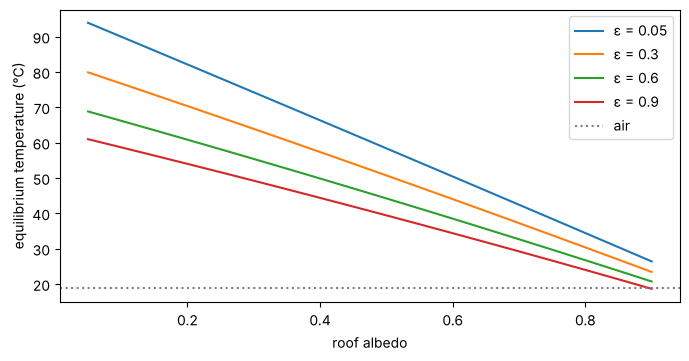

In [8]:
albedos = np.linspace(0.05, 0.9, 18)
fig, ax = plt.subplots(figsize=(8, 3.8))
for eps in (0.05, 0.3, 0.6, 0.9):          # ◀ parameter: roof emissivities
    ax.plot(albedos, [t_equilibrium(a, eps) for a in albedos], label=f"ε = {eps}")
ax.axhline(Ta - 273.15, color="gray", ls=":", label="air")
ax.set(xlabel="roof albedo", ylabel="equilibrium temperature (°C)"); ax.legend(); plt.show()

> **✏️ Task 5.** What temperature would a roof with the albedo of the built-up area in your window have, and a white roof (albedo 0.8, ε 0.9)? Why is polished sheet metal with albedo 0.6 (ε 0.05) so much warmer than a coating with the same albedo and emissivity 0.9? What properties should an ideal coating have at 0.3–2.5 µm and at 8–13 µm?

*Your answer:* 

> **✏️ Task 6.** Pick another hour from the `met` table, for instance the warmest one, and put it in place of `row` (e.g. `row = met.loc[met.temperature_2m.idxmax()]` for the warmest hour). How do the ranking and the temperatures of the surfaces change? The model gives snow a temperature above 0 °C: why is that impossible in reality, and what does the surplus energy go into? Why does snow still not melt immediately in spring sunshine even though S is high?

*Your answer:* 

---
### Data sources and references

- Copernicus Sentinel-2 data 2024, ESA, processed by ESA (L2A, Sen2Cor); COG copy in the AWS Open Data registry (`sentinel-cogs`), Earth Search catalogue (Element 84). Free use with attribution under the [Legal notice on the use of Copernicus Sentinel Data](https://sentinels.copernicus.eu/documents/247904/690755/Sentinel_Data_Legal_Notice).
- Zanaga, D. et al. (2022). *ESA WorldCover 10 m 2021 v200*. Zenodo. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Weather: Open-Meteo.com, ICON/ECMWF models as available (CC BY 4.0). https://open-meteo.com
- Narrowband to broadband albedo: Liang, S. (2001). Narrowband to broadband conversions of land surface albedo I: Algorithms. *Remote Sensing of Environment* 76, 213–238. https://doi.org/10.1016/S0034-4257(00)00205-4
- Clear-sky longwave radiation: Brutsaert, W. (1975). On a derivable formula for long-wave radiation from clear skies. *Water Resources Research* 11, 742–744. https://doi.org/10.1029/WR011i005p00742
- Convective heat transfer coefficient h = 5.7 + 3.8 · u: McAdams, W. H. (1954). *Heat Transmission*, 3rd ed. McGraw-Hill (as given in Duffie, J. A., Beckman, W. A., *Solar Engineering of Thermal Processes*).

### How to cite

OpenSkyLab (2026). Where sunlight goes: surface balance from Sentinel-2 [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/radiation_balance_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*